paper rujukan : 10.1109/ICPR.2004.1333992

dataset : vafaeii/cdnet-2014-change-detection-benchmark-dataset

In [ ]:
import os, subprocess
import os, cv2, numpy as np
import glob
import matplotlib.pyplot as plt
from google.colab import userdata
from google.colab import drive

kaggle setup

In [ ]:
!pip install -q --upgrade kaggle

os.environ.pop("KAGGLE_USERNAME", None)
os.environ.pop("KAGGLE_KEY", None)
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

!kaggle --version
!kaggle datasets list -s cdnet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 4.0 MB/s eta 0:00:00
Kaggle CLI 2.2.4
ref                                       title                          size  lastUpdated                 downloadCount  voteCount  usabilityRating  
----------------------------------------  -----------------------  ----------  --------------------------  -------------  ---------  ---------------  
maamri95/cdnet2014                        Change Detection 2014    3918157933  2020-06-27 21:27:08.630000           4140         24  0.8125           
amitsahoo1516/multi-scene-dataset         multi_scene _dataset      647295728  2026-09-19 16:09:42.313000              2          6  0.8125           
vishnureddy25/crack-detection-dataset     sccdnetcorrected          621958708  2023-10-31 04:18:51.857000             30          0  0.5              
madhusudandas/cdnet50-5300                cdnet50_5300             4084410880  2025-08-24 19:41:21.293000              5          0  0.125          

download data

In [ ]:
drive.mount("/content/drive")

CATEGORIES = ["dynamicBackground", "shadow", "badWeather"]
LOCAL_ROOT = "/content/cdnet"
DATA_DIR   = f"{LOCAL_ROOT}/dataset"
DRIVE_DIR  = "/content/drive/MyDrive/cdnet2014"
DRIVE_ZIP  = f"{DRIVE_DIR}/cdnet_3cat.zip"
KAGGLE_ZIP = "/content/cdnet2014.zip"


def sh(cmd):
    subprocess.run(cmd, shell=True, check=True)

def data_ready():
    return all(os.path.isdir(f"{DATA_DIR}/{c}") for c in CATEGORIES)

if data_ready():
    print("Data sudah ready")
elif os.path.exists(DRIVE_ZIP):
    print("Ekstrak dari zip")
    sh(f"unzip -q -o {DRIVE_ZIP} -d {LOCAL_ROOT}")
else:
    print("Downloading")
    sh(f"kaggle datasets download -d maamri95/cdnet2014 -p /content")
    patterns = " ".join(f'"dataset/{c}/*"' for c in CATEGORIES)
    sh(f"unzip -q -o {KAGGLE_ZIP} {patterns} -d {LOCAL_ROOT}")
    sh(f"rm {KAGGLE_ZIP}")
    os.makedirs(DRIVE_DIR, exist_ok=True)
    sh(f"cd {LOCAL_ROOT} && zip -qr {DRIVE_ZIP} dataset")
    print("Simpan di Drive.")

assert data_ready(), "Ada kategori yang belum terekstrak"
print("Data:", sorted(os.listdir(DATA_DIR)))

Mounted at /content/drive
Ekstrak dari zip
Data: ['badWeather', 'dynamicBackground', 'shadow']


cek ROI dan total frame

In [ ]:
for p in sorted(glob.glob(f"{DATA_DIR}/*/*/temporalROI.txt")):
    video = p.split("/")[-2]
    n_frames = len(glob.glob(p.replace("temporalROI.txt", "input/*.jpg")))
    print(f"{video:15s} {open(p).read().strip():12s} total frame: {n_frames}")

blizzard        900 7000     total frame: 7000
skating         800 3900     total frame: 3900
snowFall        800 6500     total frame: 6500
wetSnow         500 3500     total frame: 3500
boats           1900 7999    total frame: 7999
canoe           800 1189     total frame: 1189
fall            1000 4000    total frame: 4000
fountain01      400 1184     total frame: 1184
fountain02      500 1499     total frame: 1499
overpass        1000 3000    total frame: 3000
backdoor        400 2000     total frame: 2000
bungalows       300 1700     total frame: 1700
busStation      300 1250     total frame: 1250
copyMachine     500 3400     total frame: 3400
cubicle         1100 7400    total frame: 7400
peopleInShade   250 1199     total frame: 1199


In [ ]:
video_dir = f"{DATA_DIR}/shadow/backdoor"

roi = cv2.imread(os.path.join(video_dir, "ROI.bmp"), cv2.IMREAD_GRAYSCALE)
assert roi is not None, f"Gagal membaca ROI di {video_dir}"
print(roi.shape, roi.dtype)
print(np.unique(roi))

(240, 320) uint8
[  0 255]


In [ ]:
path = os.path.join(video_dir, "temporalROI.txt")
with open(path) as f:
    teks = f.read()

print(repr(teks))

'400 2000'


In [ ]:
class CDnetVideo:
    def __init__(self, video_dir):
        self.dir = video_dir
        self.name = os.path.basename(video_dir)
        self.category = os.path.basename(os.path.dirname(video_dir))

        self.roi = cv2.imread(os.path.join(self.dir, "ROI.bmp"), cv2.IMREAD_GRAYSCALE)

        path = os.path.join(self.dir, "temporalROI.txt")
        with open(path) as f:
          teks = f.read()

        print(repr(teks))

        self.eval_start, self.eval_end = map(int, teks.split())

    def is_eval(self, i):
        return self.eval_start <= i <= self.eval_end

    def frames(self):
        i = 1
        while True:
            if i > self.eval_end:
                break
            img = cv2.imread(os.path.join(self.dir, "input", f"in{i:06d}.jpg"))
            if img is None:
                break

            gt = None
            if self.is_eval(i):
                gt = cv2.imread(os.path.join(self.dir, "groundtruth", f"gt{i:06d}.png"), cv2.IMREAD_GRAYSCALE)
                assert gt is not None, f"Gagal membaca groundtruth frame {i} di {self.dir}"

            yield i, img, gt
            i += 1

In [ ]:
v = CDnetVideo(f"{DATA_DIR}/shadow/backdoor")
print(v.category, v.name, v.roi.shape, v.eval_start, v.eval_end)

for i, img, gt in v.frames():
    if i in (1, 2, v.eval_start - 1, v.eval_start, v.eval_start + 1):
        print(i, img.shape, None if gt is None else (gt.shape, sorted(set(gt.flatten()))))
    if i > v.eval_start + 1:
        break

'400 2000'
shadow backdoor (240, 320) 400 2000
1 (240, 320, 3) None
2 (240, 320, 3) None
399 (240, 320, 3) None
400 (240, 320, 3) ((240, 320), [np.uint8(0), np.uint8(85)])
401 (240, 320, 3) ((240, 320), [np.uint8(0), np.uint8(85)])


In [ ]:
def confusion(pred, gt):
    gt_pos   = (gt == 255)
    gt_neg   = (gt == 0) | (gt == 50)
    pred_pos = (pred == 255)
    pred_neg = (pred != 255)

    TP = np.count_nonzero(pred_pos & gt_pos)
    FP = np.count_nonzero(pred_pos & gt_neg)
    TN = np.count_nonzero(pred_neg & gt_neg)
    FN = np.count_nonzero(pred_neg & gt_pos)
    return TP, FP, TN, FN

In [ ]:
print(confusion(255,255))

(1, 0, 0, 0)


In [ ]:
def safe_div(a, b):
    return 0 if b == 0 else a / b

In [ ]:
def metrics(TP, FP, TN, FN):
    recall      = safe_div(TP, (TP + FN))
    specificity = safe_div(TN, (TN + FP))
    fpr         = safe_div(FP, (FP + TN))
    fnr         = safe_div(FN, (FN + TP))
    pwc         = 100 * safe_div((FN + FP) , (TP + FN + FP + TN))
    precision   = safe_div(TP , (TP + FP))
    f_measure   = 2 * precision * safe_div(recall , (precision + recall))
    return dict(Recall=recall, Specificity=specificity, FPR=fpr, FNR=fnr,
                PWC=pwc, Precision=precision, F=f_measure)

In [ ]:
print(metrics(1, 2, 1, 2))

{'Recall': 0.3333333333333333, 'Specificity': 0.3333333333333333, 'FPR': 0.6666666666666666, 'FNR': 0.6666666666666666, 'PWC': 66.66666666666666, 'Precision': 0.3333333333333333, 'F': 0.3333333333333333}


In [ ]:
class Evaluator:
    def __init__(self):
        self.TP = self.FP = self.TN = self.FN = 0

    def update(self, pred, gt):
        TP, FP, TN, FN = confusion(pred, gt)
        self.TP += TP
        self.FP += FP
        self.TN += TN
        self.FN += FN

    def result(self):
        m = metrics(self.TP, self.FP, self.TN, self.FN)
        counts = dict(TP=self.TP, FP=self.FP, TN=self.TN, FN=self.FN)
        return {**counts, **m}


In [ ]:
v = CDnetVideo(f"{DATA_DIR}/shadow/backdoor")

ev_perfect = Evaluator()
ev_lazy = Evaluator()

for i, img, gt in v.frames():
    if gt is None:
        continue
    perfect = np.where(gt == 255, 255, 0).astype(np.uint8)
    lazy    = np.zeros_like(gt)
    ev_perfect.update(perfect, gt)
    ev_lazy.update(lazy, gt)

print("perfect:", ev_perfect.result())
print("lazy:   ", ev_lazy.result())

'400 2000'
perfect: {'TP': 2024597, 'FP': 0, 'TN': 99827787, 'FN': 0, 'Recall': 1.0, 'Specificity': 1.0, 'FPR': 0.0, 'FNR': 0.0, 'PWC': 0.0, 'Precision': 1.0, 'F': 1.0}
lazy:    {'TP': 0, 'FP': 0, 'TN': 99827787, 'FN': 2024597, 'Recall': 0.0, 'Specificity': 1.0, 'FPR': 0.0, 'FNR': 1.0, 'PWC': 1.9877757598683206, 'Precision': 0, 'F': 0}


In [ ]:
class RunningAverage:
    def __init__(self, alpha=0.01, tau=30):
        self.alpha = alpha
        self.tau = tau
        self.B = None

    def apply(self, frame):
        I = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY).astype(np.float32)

        if self.B is None:
            self.B = I
            return np.zeros(I.shape, dtype=np.uint8)

        mask = np.where(np.abs(I - self.B) > self.tau, 255, 0).astype(np.uint8)

        self.B = self.alpha * I + (1 - self.alpha) * self.B

        return mask

In [ ]:
v = CDnetVideo(f"{DATA_DIR}/shadow/backdoor")
model = RunningAverage(alpha=0.01, tau=30)
ev = Evaluator()

for i, img, gt in v.frames():
    mask = model.apply(img)
    if gt is not None:
        ev.update(mask, gt)

print(ev.result())

'400 2000'
{'TP': 1531930, 'FP': 711943, 'TN': 99115844, 'FN': 492667, 'Recall': 0.7566592265028547, 'Specificity': 0.9928682882652703, 'FPR': 0.00713171173472973, 'FNR': 0.24334077349714536, 'PWC': 1.1827018207055418, 'Precision': 0.6827168917313948, 'F': 0.7177888095734537}


In [ ]:
def show_result(img, gt, mask, title=""):
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    err = np.zeros((*gt.shape, 3), dtype=np.uint8)
    pred_pos = (mask == 255)
    gt_pos   = (gt == 255)
    gt_neg   = (gt == 0) | (gt == 50)
    err[pred_pos & gt_pos] = (0, 200, 0)
    err[pred_pos & gt_neg] = (220, 0, 0)
    err[~pred_pos & gt_pos] = (0, 80, 255)
    err[(gt == 85) | (gt == 170)] = (60, 60, 60)

    panels = [(rgb, "Input"), (gt, "Ground truth"), (mask, "Mask model"), (err, "TP / FP / FN")]
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    for ax, (im, name) in zip(axes, panels):
        ax.imshow(im, cmap="gray" if im.ndim == 2 else None, vmin=0, vmax=255)
        ax.set_title(name)
        ax.axis("off")
    fig.suptitle(title)
    plt.show()

'400 2000'
mulai, eval: 400 2000
menampilkan frame 600 gt None? False


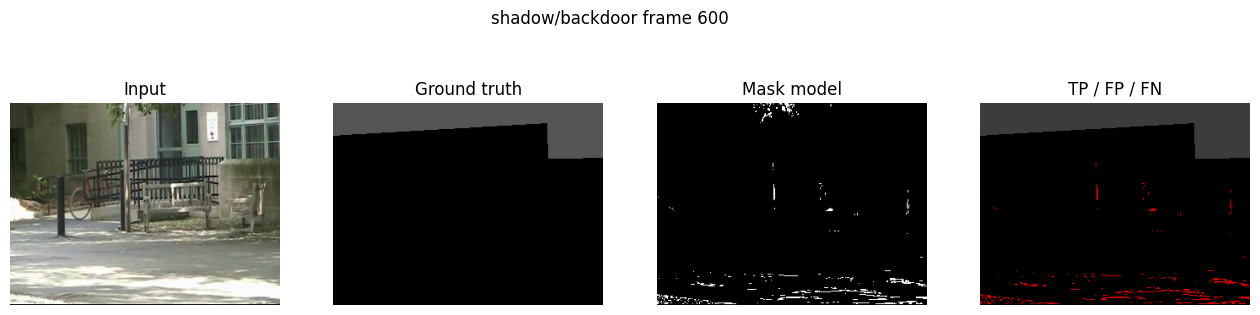

menampilkan frame 1200 gt None? False


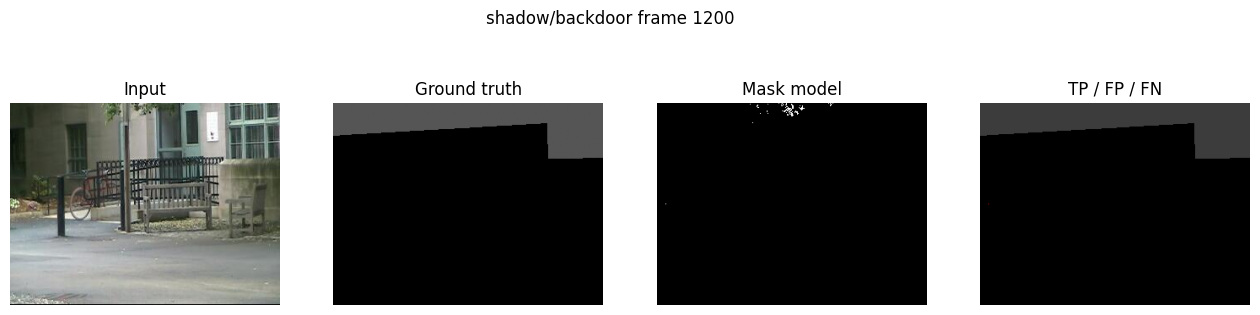

menampilkan frame 1800 gt None? False


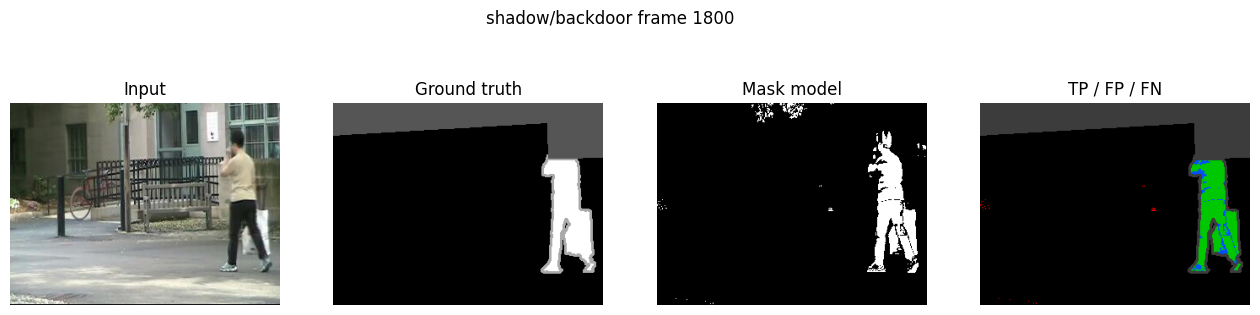

selesai, frame terakhir: 2000


In [ ]:
v = CDnetVideo(f"{DATA_DIR}/shadow/backdoor")
model = RunningAverage(alpha=0.01, tau=30)
tampilkan = {600, 1200, 1800}

print("mulai, eval:", v.eval_start, v.eval_end)
last_i = None
for i, img, gt in v.frames():
    last_i = i
    mask = model.apply(img)
    if i in tampilkan:
        print("menampilkan frame", i, "gt None?", gt is None)
        show_result(img, gt, mask, title=f"{v.category}/{v.name} frame {i}")
print("selesai, frame terakhir:", last_i)

In [ ]:
import torch, time, json

DEV = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEV, "| torch threads:", torch.get_num_threads())


class GMMStaufferGrimson:
    """GMM per piksel (Stauffer & Grimson, 1999), dikerjakan serentak untuk semua piksel.

    - ruang warna RGB, satu varians per komponen
    - varians dihitung dari jarak kuadrat total tiga kanal ||x - mu||^2
      (sama seperti BackgroundSubtractorMOG di OpenCV), batas bawah 15^2
    - matching: ||x - mu_k||^2 < lam^2 * var_k (lam = 2.5)
    - w_k <- (1 - alpha) w_k + alpha M_k
    - rho = alpha / w_k (rho = alpha * eta(x | mu, sigma) versi asli bernilai
      sangat kecil sehingga mean nyaris tidak bergerak)
    - komponen diurutkan menurut w / sigma, B komponen pertama dengan
      jumlah bobot > T dianggap latar
    """

    def __init__(self, K=3, alpha=0.01, T=0.7, sigma0=30.0, w0=0.05,
                 lam=2.5, var_min=15.0 ** 2, device=DEV):
        self.K, self.alpha, self.T = K, alpha, T
        self.var0, self.w0, self.lam2 = sigma0 ** 2, w0, lam ** 2
        self.var_min, self.dev = var_min, device
        self.mu = None

    def _init(self, x):
        N, K = x.shape[0], self.K
        self.mu = torch.zeros(N, K, 3, device=self.dev)
        self.mu[:, 0] = x
        self.var = torch.full((N, K), self.var0, device=self.dev)
        self.w = torch.zeros(N, K, device=self.dev)
        self.w[:, 0] = 1.0
        self.rows = torch.arange(N, device=self.dev)

    @torch.no_grad()
    def apply(self, frame):
        h, w_ = frame.shape[:2]
        x = torch.from_numpy(frame.reshape(-1, 3)).to(self.dev, torch.float32)
        if self.mu is None:
            self._init(x)
            return np.zeros((h, w_), np.uint8)

        K, a = self.K, self.alpha
        d2 = ((x[:, None, :] - self.mu) ** 2).sum(-1)              # N x K
        match = (d2 < self.lam2 * self.var) & (self.w > 0)
        has = match.any(1)
        idx = torch.argmax(match.to(torch.uint8), 1)                # komponen cocok pertama

        # B = jumlah komponen latar: b terkecil dengan sum_{k<=b} w_k > T
        B = (torch.cumsum(self.w, 1) <= self.T).sum(1) + 1
        fg = (~has) | (idx >= B)

        # pembaruan bobot
        M = torch.zeros_like(self.w)
        r, k = self.rows[has], idx[has]
        M[r, k] = 1.0
        self.w = (1 - a) * self.w + a * M

        # pembaruan mean dan varians komponen yang cocok
        rho = (a / self.w[r, k]).clamp(max=1.0)
        mu_new = self.mu[r, k] + rho[:, None] * (x[r] - self.mu[r, k])
        d = x[r] - mu_new
        var_new = (1 - rho) * self.var[r, k] + rho * (d * d).sum(-1)
        self.mu[r, k] = mu_new
        self.var[r, k] = var_new.clamp(min=self.var_min)

        # tidak ada yang cocok: ganti komponen paling lemah (urutan terakhir)
        nm = self.rows[~has]
        self.mu[nm, K - 1] = x[nm]
        self.var[nm, K - 1] = self.var0
        self.w[nm, K - 1] = self.w0
        self.w = self.w / self.w.sum(1, keepdim=True)

        # urutkan ulang menurut w / sigma
        order = torch.argsort(self.w / self.var.sqrt(), 1, descending=True)
        self.w = torch.gather(self.w, 1, order)
        self.var = torch.gather(self.var, 1, order)
        self.mu = torch.gather(self.mu, 1, order[..., None].expand(-1, -1, 3))

        return (fg.view(h, w_).to(torch.uint8) * 255).cpu().numpy()


class MOG2:
    """Pembungkus cv2 MOG2. Keluaran: 255 objek, 127 bayangan, 0 latar."""

    def __init__(self, history=500, varThreshold=16, detectShadows=True, lr=-1):
        self.m = cv2.createBackgroundSubtractorMOG2(
            history=history, varThreshold=varThreshold, detectShadows=detectShadows)
        self.lr = lr

    def apply(self, frame):
        return self.m.apply(frame, learningRate=self.lr)


# uji cepat pada video sintetis: latar statis + kotak bergerak + piksel yang berganti dua warna
rng = np.random.default_rng(0)
g = GMMStaufferGrimson()
for t in range(300):
    f = np.full((60, 80, 3), 100, np.uint8)
    f[:, :10] = 40 if t % 2 else 200                    # latar bimodal
    f = np.clip(f + rng.normal(0, 3, f.shape), 0, 255).astype(np.uint8)
    if t >= 250:
        o = 30 + (t - 250) // 2
        f[20:40, o:o + 20] = 250                        # objek
    m = g.apply(f)
print("fg di kotak objek    :", m[20:40, 60:70].mean() / 255)
print("fg di latar bimodal  :", m[:, :10].mean() / 255)
print("fg di latar statis   :", m[:, 12:25].mean() / 255)


device: cpu | torch threads: 1
fg di kotak objek    : 1.0
fg di latar bimodal  : 0.0
fg di latar statis   : 0.0


## Eksperimen utama: 16 video, 3 metode
RA, GMM Stauffer–Grimson, dan MOG2 diproses bersama dalam satu kali baca frame. Hasil disimpan ke Drive per video sehingga bisa dilanjutkan bila runtime terputus.

In [ ]:
OUT_DIR = f"{DRIVE_DIR}/hasil"
os.makedirs(OUT_DIR, exist_ok=True)
RES_JSON = f"{OUT_DIR}/hasil_utama.json"

VIDEO_DIRS = sorted(os.path.dirname(p) for c in CATEGORIES
                    for p in glob.glob(f"{DATA_DIR}/{c}/*/temporalROI.txt"))
print(len(VIDEO_DIRS), "video")


def make_models():
    return {
        "RA": RunningAverage(alpha=0.01, tau=30),
        "GMM-SG": GMMStaufferGrimson(K=3, alpha=0.01, T=0.7, sigma0=30.0),
        "MOG2": MOG2(history=500, varThreshold=16, detectShadows=True),
    }


def run_video(vdir, models, snap_every=50):
    """Satu kali baca frame, semua model diproses bersama.
    Menyimpan satu frame contoh: frame evaluasi dengan piksel motion terbanyak."""
    v = CDnetVideo(vdir)
    evs = {n: Evaluator() for n in models}
    best = (-1, None)
    t0 = time.time()
    for i, img, gt in v.frames():
        masks = {n: m.apply(img) for n, m in models.items()}
        if gt is None:
            continue
        for n in models:
            evs[n].update(masks[n], gt)
        if i % snap_every == 0:
            pos = int((gt == 255).sum())
            if pos > best[0]:
                best = (pos, dict(i=i, img=img, gt=gt, masks=masks))
    res = {n: e.result() for n, e in evs.items()}
    return v, res, best[1], time.time() - t0


results = json.load(open(RES_JSON)) if os.path.exists(RES_JSON) else {}
for vdir in VIDEO_DIRS:
    key = f"{os.path.basename(os.path.dirname(vdir))}/{os.path.basename(vdir)}"
    if key in results and results[key].get("gmm_versi") == 2:
        print("lewati (sudah ada):", key)
        continue
    if key in results:
        # RA dan MOG2 sudah ada; ulang GMM-SG saja dengan versi varians yang diperbaiki
        v, res_g, snap, dt = run_video(vdir, {"GMM-SG": make_models()["GMM-SG"]})
        res = results[key]
        res["GMM-SG-v1"] = res["GMM-SG"]          # simpan hasil versi pertama untuk perbandingan
        res["GMM-SG"] = res_g["GMM-SG"]
        old = dict(np.load(f"{OUT_DIR}/snap_{v.category}_{v.name}.npz"))
        assert int(old["i"]) == snap["i"]
        snap["masks"] = {"RA": old["RA"], "GMM-SG": snap["masks"]["GMM-SG"], "MOG2": old["MOG2"]}
    else:
        v, res, snap, dt = run_video(vdir, make_models())
    res["gmm_versi"] = 2
    results[key] = res
    json.dump(results, open(RES_JSON, "w"), indent=1, default=float)
    np.savez_compressed(f"{OUT_DIR}/snap_{v.category}_{v.name}.npz", i=snap["i"], img=snap["img"],
                        gt=snap["gt"], **{k.replace("-", "_"): m for k, m in snap["masks"].items()})
    print(f"{key:32s} {dt/60:5.1f} mnt  F  RA {res['RA']['F']:.3f}  GMM-SG {res['GMM-SG']['F']:.3f}  MOG2 {res['MOG2']['F']:.3f}")
print("SELESAI semua video")


16 video
lewati (sudah ada): badWeather/blizzard
lewati (sudah ada): badWeather/skating
lewati (sudah ada): badWeather/snowFall
lewati (sudah ada): badWeather/wetSnow
lewati (sudah ada): dynamicBackground/boats
lewati (sudah ada): dynamicBackground/canoe
lewati (sudah ada): dynamicBackground/fall
lewati (sudah ada): dynamicBackground/fountain01
lewati (sudah ada): dynamicBackground/fountain02
lewati (sudah ada): dynamicBackground/overpass
lewati (sudah ada): shadow/backdoor
lewati (sudah ada): shadow/bungalows
lewati (sudah ada): shadow/busStation
lewati (sudah ada): shadow/copyMachine
lewati (sudah ada): shadow/cubicle
lewati (sudah ada): shadow/peopleInShade
SELESAI semua video


## Tabel hasil per video dan per kategori

In [ ]:
import pandas as pd

METHODS = ["RA", "GMM-SG", "MOG2"]
METRICS = ["Recall", "Specificity", "FPR", "FNR", "PWC", "Precision", "F"]

rows = []
for key, res in results.items():
    cat, vid = key.split("/")
    for m in METHODS:
        rows.append(dict(category=cat, video=vid, method=m, **{k: res[m][k] for k in METRICS + ["TP", "FP", "TN", "FN"]}))
df = pd.DataFrame(rows)
df.to_csv(f"{OUT_DIR}/hasil_per_video.csv", index=False)

# skor kategori = rerata skor video dalam kategori
cat_tab = df.groupby(["category", "method"])[METRICS].mean().reset_index()
cat_tab.to_csv(f"{OUT_DIR}/hasil_per_kategori.csv", index=False)

pd.set_option("display.width", 200)
print("F-measure per video")
print(df.pivot(index=["category", "video"], columns="method", values="F")[METHODS].round(4).to_string())
print()
print("F-measure rerata per kategori")
fk = df.pivot_table(index="category", columns="method", values="F", aggfunc="mean")[METHODS]
fk.loc["Rerata (3 kategori)"] = fk.mean()
print(fk.round(4).to_string())
print()
print("Tujuh metrik per kategori")
for c in CATEGORIES:
    print(c)
    print(cat_tab[cat_tab.category == c].set_index("method").loc[METHODS, METRICS].round(4).to_string())
    print()

# perbandingan GMM-SG versi pertama (varians per kanal, dibagi 3, batas bawah 4^2) dengan versi akhir
v1 = {k: r["GMM-SG-v1"]["F"] for k, r in results.items() if "GMM-SG-v1" in r}
if v1:
    cmp_ = pd.DataFrame({"GMM-SG v1": v1, "GMM-SG": {k: results[k]["GMM-SG"]["F"] for k in v1}})
    cmp_["kategori"] = [k.split("/")[0] for k in cmp_.index]
    print("F-measure GMM-SG v1 vs akhir")
    print(cmp_.round(4).to_string())
    print(cmp_.groupby("kategori").mean().round(4).to_string())
    cmp_.to_csv(f"{OUT_DIR}/gmm_v1_vs_akhir.csv")


F-measure per video
method                               RA  GMM-SG    MOG2
category          video                                
badWeather        blizzard       0.6119  0.7733  0.1109
                  skating        0.5781  0.7633  0.7440
                  snowFall       0.6655  0.6914  0.0956
                  wetSnow        0.6752  0.6652  0.5174
dynamicBackground boats          0.0790  0.0762  0.1654
                  canoe          0.2694  0.3946  0.6048
                  fall           0.1648  0.4480  0.3419
                  fountain01     0.0293  0.0649  0.0426
                  fountain02     0.3342  0.3728  0.2795
                  overpass       0.3580  0.4078  0.5477
shadow            backdoor       0.7178  0.8846  0.7149
                  bungalows      0.6993  0.7852  0.7837
                  busStation     0.5897  0.5171  0.6287
                  copyMachine    0.5457  0.4947  0.5060
                  cubicle        0.5375  0.7104  0.6815
                  peopleInSh

## Contoh kualitatif
Hijau = TP, merah = FP, biru = FN, abu-abu = tidak dinilai.

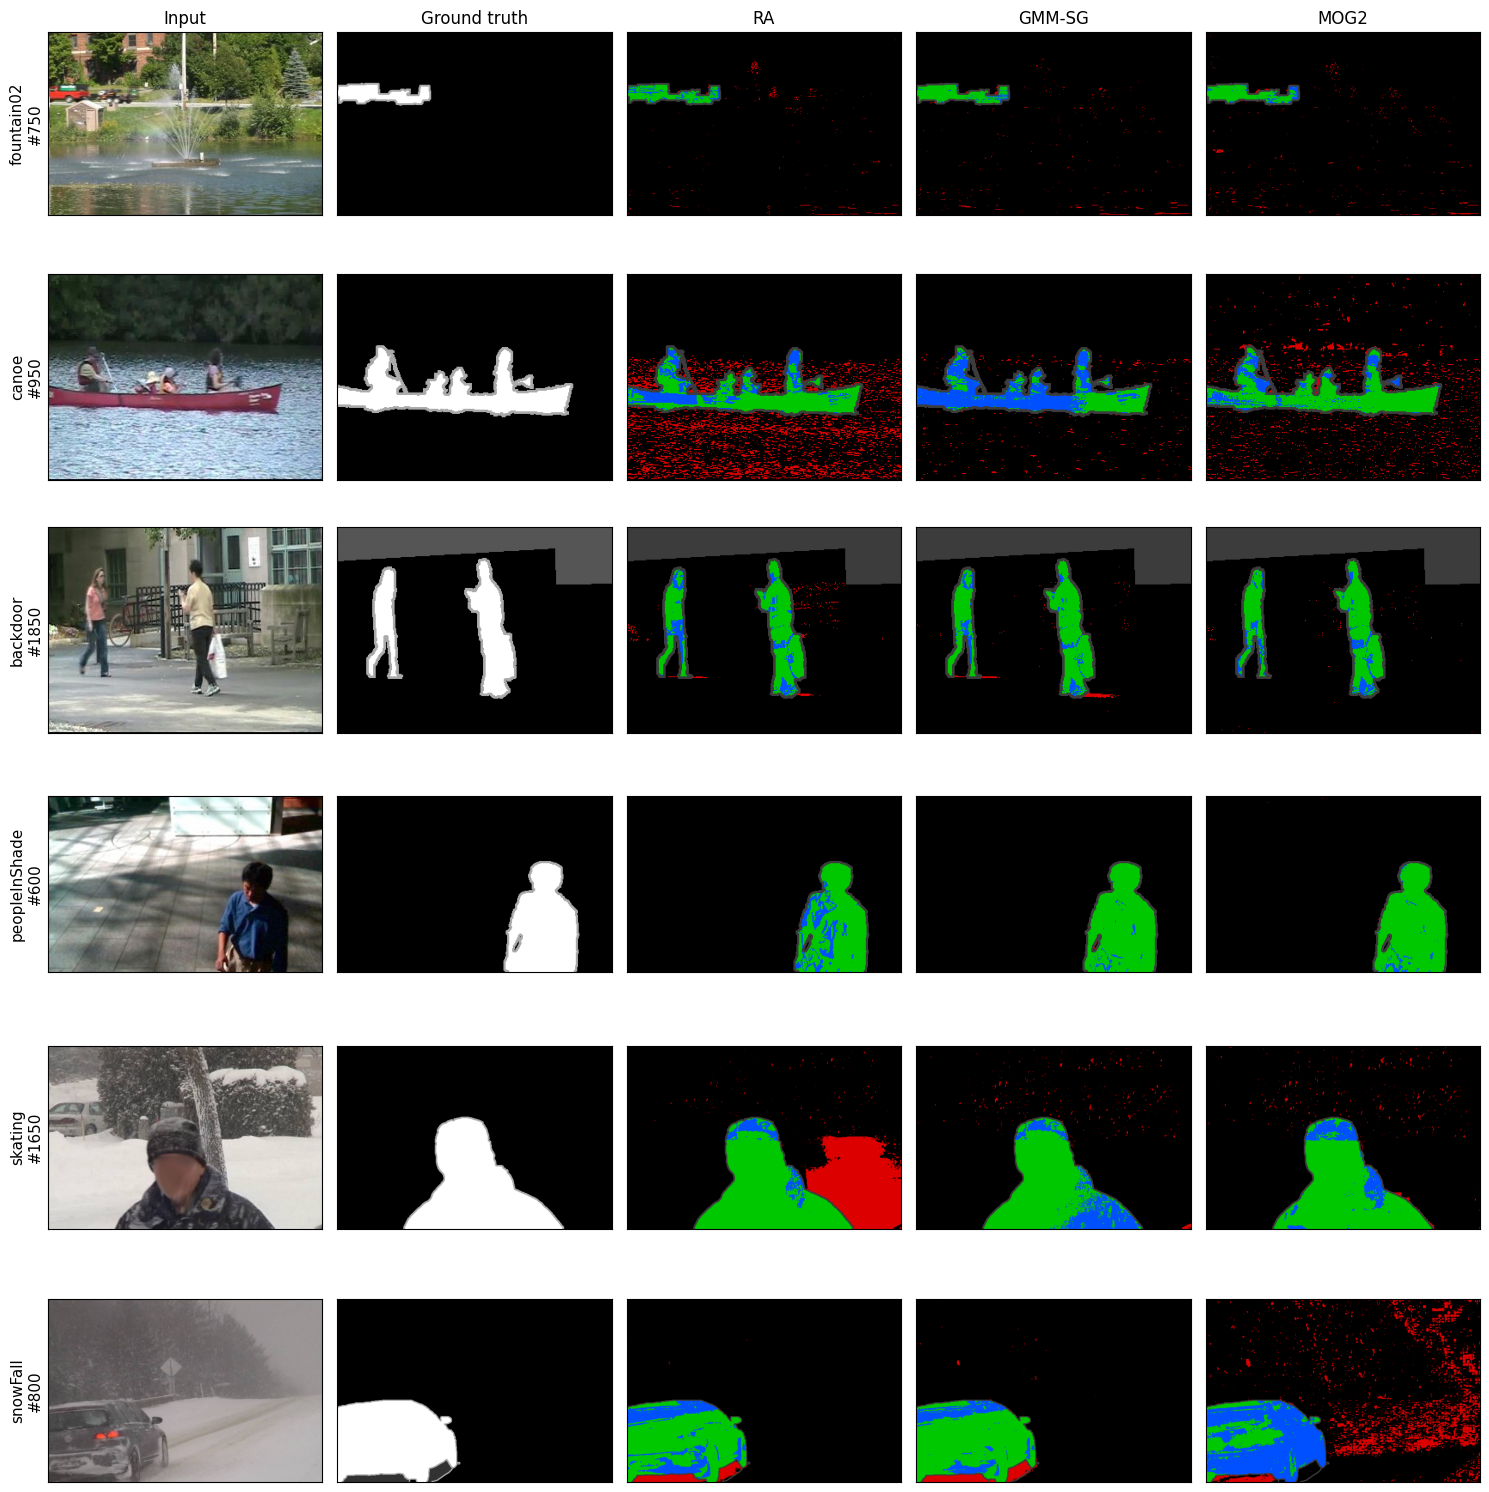

In [ ]:
def err_map(mask, gt):
    err = np.zeros((*gt.shape, 3), np.uint8)
    pp, gp = (mask == 255), (gt == 255)
    gn = (gt == 0) | (gt == 50)
    err[pp & gp] = (0, 200, 0)        # TP hijau
    err[pp & gn] = (220, 0, 0)        # FP merah
    err[~pp & gp] = (0, 80, 255)      # FN biru
    err[(gt == 85) | (gt == 170)] = (60, 60, 60)
    return err


def fig_kualitatif(keys, fname):
    cols = ["Input", "Ground truth", "RA", "GMM-SG", "MOG2"]
    fig, axes = plt.subplots(len(keys), 5, figsize=(15, 2.6 * len(keys)))
    for r, key in enumerate(keys):
        cat, vid = key.split("/")
        s = np.load(f"{OUT_DIR}/snap_{cat}_{vid}.npz")
        panels = [cv2.cvtColor(s["img"], cv2.COLOR_BGR2RGB), s["gt"],
                  err_map(s["RA"], s["gt"]), err_map(s["GMM_SG"], s["gt"]), err_map(s["MOG2"], s["gt"])]
        for c, im in enumerate(panels):
            ax = axes[r, c]
            ax.imshow(im, cmap="gray" if im.ndim == 2 else None, vmin=0, vmax=255)
            ax.set_xticks([]); ax.set_yticks([])
            if r == 0:
                ax.set_title(cols[c], fontsize=12)
            if c == 0:
                ax.set_ylabel(f"{vid}\n#{int(s['i'])}", fontsize=11)
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/{fname}", dpi=150, bbox_inches="tight")
    plt.show()


FIG_KEYS = ["dynamicBackground/fountain02", "dynamicBackground/canoe",
            "shadow/backdoor", "shadow/peopleInShade",
            "badWeather/skating", "badWeather/snowFall"]
fig_kualitatif(FIG_KEYS, "kualitatif.png")


## Sensitivitas laju pembelajaran α
Untuk MOG2, α dipasang sebagai `learningRate`.

lewati: dynamicBackground/canoe
lewati: shadow/backdoor
'500 3500'
badWeather/wetSnow selesai, 35.6 mnt


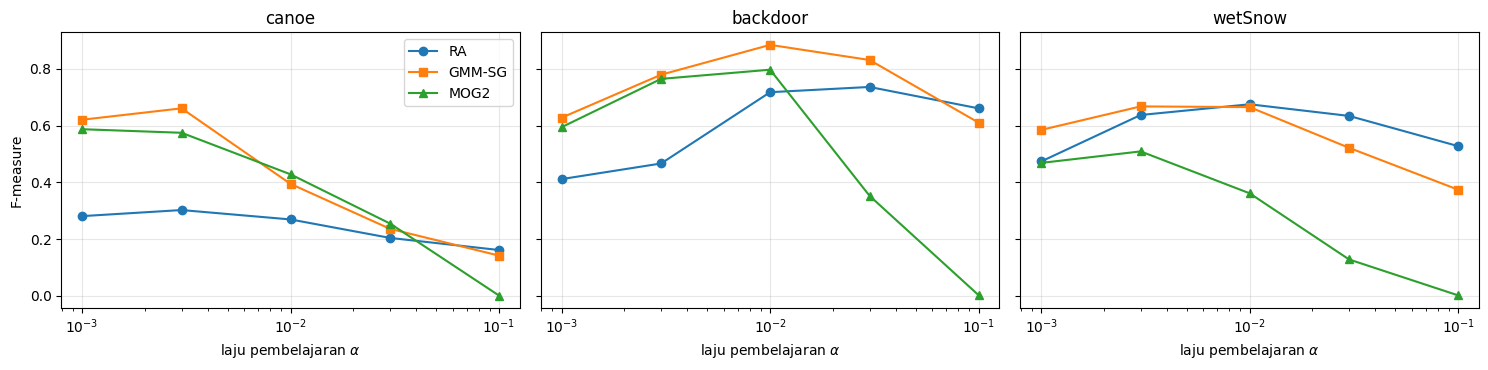

F-measure vs alpha
dynamicBackground/canoe
  RA      0.001:0.281  0.003:0.302  0.01:0.269  0.03:0.204  0.1:0.162
  GMM-SG  0.001:0.621  0.003:0.661  0.01:0.395  0.03:0.236  0.1:0.142
  MOG2    0.001:0.587  0.003:0.575  0.01:0.428  0.03:0.255  0.1:0.001
shadow/backdoor
  RA      0.001:0.412  0.003:0.467  0.01:0.718  0.03:0.736  0.1:0.661
  GMM-SG  0.001:0.628  0.003:0.779  0.01:0.885  0.03:0.831  0.1:0.611
  MOG2    0.001:0.595  0.003:0.765  0.01:0.797  0.03:0.353  0.1:0.003
badWeather/wetSnow
  RA      0.001:0.474  0.003:0.637  0.01:0.675  0.03:0.634  0.1:0.528
  GMM-SG  0.001:0.585  0.003:0.668  0.01:0.665  0.03:0.522  0.1:0.374
  MOG2    0.001:0.469  0.003:0.509  0.01:0.362  0.03:0.128  0.1:0.002


In [ ]:
SWEEP_JSON = f"{OUT_DIR}/sensitivitas_alpha.json"
ALPHAS = [0.001, 0.003, 0.01, 0.03, 0.1]
SWEEP_VIDEOS = ["dynamicBackground/canoe", "shadow/backdoor", "badWeather/wetSnow"]

sweep = json.load(open(SWEEP_JSON)) if os.path.exists(SWEEP_JSON) else {}
for key in SWEEP_VIDEOS:
    if key in sweep:
        print("lewati:", key)
        continue
    models = {}
    for a in ALPHAS:
        models[f"RA|{a}"] = RunningAverage(alpha=a, tau=30)
        models[f"GMM-SG|{a}"] = GMMStaufferGrimson(K=3, alpha=a, T=0.7, sigma0=30.0)
        models[f"MOG2|{a}"] = MOG2(history=500, varThreshold=16, detectShadows=True, lr=a)
    _, res, _, dt = run_video(f"{DATA_DIR}/{key}", models, snap_every=10**9)
    sweep[key] = {n: r["F"] for n, r in res.items()}
    json.dump(sweep, open(SWEEP_JSON, "w"), indent=1, default=float)
    print(f"{key} selesai, {dt/60:.1f} mnt")

fig, axes = plt.subplots(1, len(SWEEP_VIDEOS), figsize=(15, 3.8), sharey=True)
for ax, key in zip(axes, SWEEP_VIDEOS):
    for m, mk in zip(METHODS, ["o-", "s-", "^-"]):
        ax.plot(ALPHAS, [sweep[key][f"{m}|{a}"] for a in ALPHAS], mk, label=m)
    ax.set_xscale("log")
    ax.set_xlabel(r"laju pembelajaran $\alpha$")
    ax.set_title(key.split("/")[1])
    ax.grid(alpha=0.3)
axes[0].set_ylabel("F-measure")
axes[0].legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/sensitivitas_alpha.png", dpi=150, bbox_inches="tight")
plt.show()

print("F-measure vs alpha")
for key in SWEEP_VIDEOS:
    print(key)
    for m in METHODS:
        print(f"  {m:7s}", "  ".join(f"{a:g}:{sweep[key][f'{m}|{a}']:.3f}" for a in ALPHAS))


## Analisis kesalahan: badWeather dan piksel bayangan

In [ ]:
# (a) Precision dan Recall per video untuk kategori badWeather
for key in sorted(k for k in results if k.startswith("badWeather")):
    print(key, "  ".join(f"{m}: Re {results[key][m]['Recall']:.3f} Pr {results[key][m]['Precision']:.3f}" for m in METHODS))
print()

# (b) Kesalahan pada piksel hard shadow (GT = 50) di kategori shadow
SHADOW_JSON = f"{OUT_DIR}/analisis_bayangan.json"
shadow_res = json.load(open(SHADOW_JSON)) if os.path.exists(SHADOW_JSON) else {}
for vdir in [d for d in VIDEO_DIRS if "/shadow/" in d]:
    key = "shadow/" + os.path.basename(vdir)
    if key in shadow_res:
        continue
    v = CDnetVideo(vdir)
    models = make_models()
    cnt = {m: {"fp_shadow": 0, "fp_lain": 0, "lbl127": 0} for m in models}
    n_shadow = n_static = 0
    for i, img, gt in v.frames():
        masks = {n: m.apply(img) for n, m in models.items()}
        if gt is None:
            continue
        sh, st = (gt == 50), (gt == 0)
        n_shadow += int(sh.sum()); n_static += int(st.sum())
        for n, mk in masks.items():
            cnt[n]["fp_shadow"] += int(((mk == 255) & sh).sum())
            cnt[n]["fp_lain"] += int(((mk == 255) & st).sum())
            cnt[n]["lbl127"] += int(((mk == 127) & sh).sum())
    shadow_res[key] = dict(n_shadow=n_shadow, n_static=n_static, **cnt)
    json.dump(shadow_res, open(SHADOW_JSON, "w"), indent=1)

print("Bagian FP yang jatuh di piksel bayangan, dan laju FP di piksel bayangan vs piksel statis")
for key, r in shadow_res.items():
    line = f"{key:22s} piksel bayangan {r['n_shadow']:>9d} |"
    for m in METHODS:
        c = r[m]
        fp_tot = c["fp_shadow"] + c["fp_lain"]
        line += (f" {m}: porsi {c['fp_shadow'] / max(fp_tot, 1):.2f}"
                 f" lajuSh {c['fp_shadow'] / max(r['n_shadow'], 1):.3f}"
                 f" lajuSt {c['fp_lain'] / max(r['n_static'], 1):.4f} |")
    line += f" MOG2 label127 di bayangan {r['MOG2']['lbl127'] / max(r['n_shadow'], 1):.3f}"
    print(line)


badWeather/blizzard RA: Re 0.442 Pr 0.994  GMM-SG: Re 0.637 Pr 0.985  MOG2: Re 0.061 Pr 0.640
badWeather/skating RA: Re 0.839 Pr 0.441  GMM-SG: Re 0.737 Pr 0.791  MOG2: Re 0.752 Pr 0.736
badWeather/snowFall RA: Re 0.539 Pr 0.869  GMM-SG: Re 0.599 Pr 0.817  MOG2: Re 0.163 Pr 0.068
badWeather/wetSnow RA: Re 0.573 Pr 0.821  GMM-SG: Re 0.564 Pr 0.812  MOG2: Re 0.426 Pr 0.659

'400 2000'
'300 1700'
'300 1250'
'500 3400'
'1100 7400'
'250 1199'
Bagian FP yang jatuh di piksel bayangan, dan laju FP di piksel bayangan vs piksel statis
shadow/backdoor        piksel bayangan         0 | RA: porsi 0.00 lajuSh 0.000 lajuSt 0.0071 | GMM-SG: porsi 0.00 lajuSh 0.000 lajuSt 0.0019 | MOG2: porsi 0.00 lajuSh 0.000 lajuSt 0.0089 | MOG2 label127 di bayangan 0.000
shadow/bungalows       piksel bayangan   1753264 | RA: porsi 0.90 lajuSh 1.000 lajuSt 0.0026 | GMM-SG: porsi 0.98 lajuSh 1.000 lajuSt 0.0004 | MOG2: porsi 0.94 lajuSh 0.999 lajuSt 0.0014 | MOG2 label127 di bayangan 0.001
shadow/busStation      piks

### MOG2 di badWeather: dengan dan tanpa deteksi bayangan

In [ ]:
# Mengapa MOG2 lemah di badWeather? Bandingkan detectShadows=True vs False,
# dan hitung ke label apa piksel objek (GT = 255) jatuh pada MOG2 dengan deteksi bayangan.
BW_JSON = f"{OUT_DIR}/mog2_badweather.json"
bw = json.load(open(BW_JSON)) if os.path.exists(BW_JSON) else {}
for vdir in [d for d in VIDEO_DIRS if "/badWeather/" in d]:
    key = "badWeather/" + os.path.basename(vdir)
    if key in bw:
        continue
    v = CDnetVideo(vdir)
    m_on = MOG2(history=500, varThreshold=16, detectShadows=True)
    m_off = MOG2(history=500, varThreshold=16, detectShadows=False)
    ev_on, ev_off = Evaluator(), Evaluator()
    lab = {"255": 0, "127": 0, "0": 0}
    for i, img, gt in v.frames():
        a, b = m_on.apply(img), m_off.apply(img)
        if gt is None:
            continue
        ev_on.update(a, gt); ev_off.update(b, gt)
        pos = (gt == 255)
        for k in lab:
            lab[k] += int(((a == int(k)) & pos).sum())
    n = max(sum(lab.values()), 1)
    bw[key] = dict(on=ev_on.result(), off=ev_off.result(), objek_ke_label={k: c / n for k, c in lab.items()})
    json.dump(bw, open(BW_JSON, "w"), indent=1, default=float)

for key, r in bw.items():
    print(f"{key:22s} F on {r['on']['F']:.3f} (Re {r['on']['Recall']:.3f} Pr {r['on']['Precision']:.3f}) | "
          f"F off {r['off']['F']:.3f} (Re {r['off']['Recall']:.3f} Pr {r['off']['Precision']:.3f}) | "
          f"piksel objek -> 255: {r['objek_ke_label']['255']:.3f}, 127: {r['objek_ke_label']['127']:.3f}, 0: {r['objek_ke_label']['0']:.3f}")


'900 7000'
'800 3900'
'800 6500'
'500 3500'
badWeather/blizzard    F on 0.111 (Re 0.061 Pr 0.640) | F off 0.762 (Re 0.764 Pr 0.760) | piksel objek -> 255: 0.061, 127: 0.703, 0: 0.236
badWeather/skating     F on 0.744 (Re 0.752 Pr 0.736) | F off 0.793 (Re 0.870 Pr 0.729) | piksel objek -> 255: 0.752, 127: 0.118, 0: 0.130
badWeather/snowFall    F on 0.096 (Re 0.163 Pr 0.068) | F off 0.362 (Re 0.797 Pr 0.234) | piksel objek -> 255: 0.163, 127: 0.633, 0: 0.203
badWeather/wetSnow     F on 0.517 (Re 0.426 Pr 0.659) | F off 0.666 (Re 0.704 Pr 0.632) | piksel objek -> 255: 0.426, 127: 0.278, 0: 0.296


In [ ]:
# Unduh hasil (png, csv, json)
import zipfile
from google.colab import files

ZIP = "/content/hasil_cdnet.zip"
with zipfile.ZipFile(ZIP, "w") as z:
    for p in sorted(glob.glob(f"{OUT_DIR}/*")):
        if p.endswith((".png", ".csv", ".json")):
            z.write(p, os.path.basename(p))
print(zipfile.ZipFile(ZIP).namelist())
files.download(ZIP)


['analisis_bayangan.json', 'gmm_v1_vs_akhir.csv', 'hasil_per_kategori.csv', 'hasil_per_video.csv', 'hasil_utama.json', 'kualitatif.png', 'mog2_badweather.json', 'sensitivitas_alpha.json', 'sensitivitas_alpha.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>